In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Big Dataset.xlsx", index_col=0)

In [3]:
df.dropna(inplace=True)

In [4]:
df_plot = df[['comp','season','home GF','away GF']]

In [5]:
df_plot.dropna(inplace=True)

C:\Users\dmsta\AppData\Local\Temp\ipykernel_15248\2177156303.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot.dropna(inplace=True)


In [6]:
df_plot = df_plot[df_plot['comp'] == 'Premier League']

In [7]:
df_plot.reset_index(drop=True, inplace=True)

In [8]:
df_plot = df_plot[df_plot['season'] != 2023]

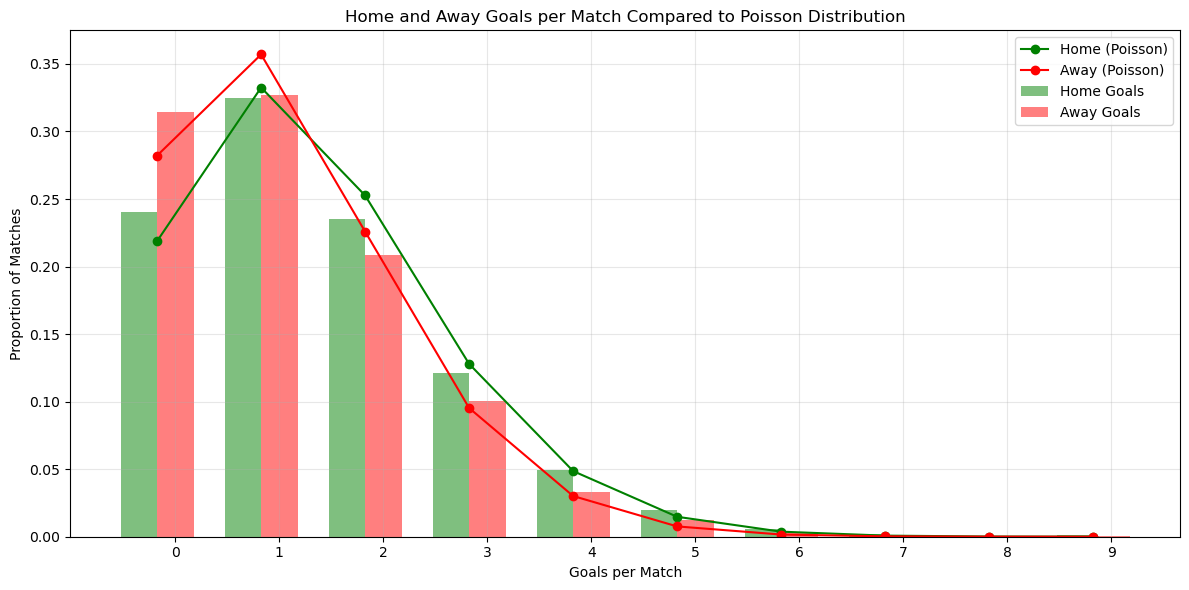

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# Assuming df_plot is your dataframe
# Calculate average goals
avg_home_goals = df_plot['home GF'].mean()
avg_away_goals = df_plot['away GF'].mean()

# Generate x values for Poisson distribution
x = np.arange(0, 10)

# Calculate Poisson probabilities
home_poisson = poisson.pmf(x, avg_home_goals)#.round(2)
away_poisson = poisson.pmf(x, avg_away_goals)#.round(2)

# Calculate actual proportions
home_proportions = df_plot['home GF'].value_counts(normalize=True).sort_index()
away_proportions = df_plot['away GF'].value_counts(normalize=True).sort_index()
away_proportions = away_proportions.reindex(away_proportions.index.union([8.0])).fillna(0)

# Plotting
plt.figure(figsize=(12, 6))

# Set width of bars
bar_width = 0.35

# Set position of bar on X axis
r1 = np.arange(len(x))
r2 = [x + bar_width for x in r1]

# Plot bars
plt.bar(r1, home_proportions, color='green', width=bar_width, alpha=0.5, label='Home Goals')
plt.bar(r2, away_proportions, color='red', width=bar_width, alpha=0.5, label='Away Goals')

# Plot Poisson distributions
plt.plot([x + bar_width/2 for x in r1], home_poisson, color='green', marker='o', label='Home (Poisson)')
plt.plot([x + bar_width/2 for x in r1], away_poisson, color='red', marker='o', label='Away (Poisson)')

# Add xticks on the middle of the group bars
plt.xlabel('Goals per Match')
plt.ylabel('Proportion of Matches')
plt.title('Home and Away Goals per Match Compared to Poisson Distribution')
plt.xticks([r + bar_width for r in range(len(x))], x)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Goals Compared to Poisson.png", dpi=300)
plt.show()

In [94]:
df_plot["away GF"].var()

1.4751652966325643

In [10]:
avg_away_goals

1.2653282691264243

In [11]:
df_plot[df_plot['away GF'] == 0].shape[0] / df_plot.shape[0]

0.31470428648941945

In [12]:
df_plot[df_plot['home GF'] <= 3].shape[0] / df_plot.shape[0]

0.9213239283776451

In [13]:
# number of games that finish 1-1
df_plot[(df_plot['home GF'] <= 3) & (df_plot['away GF'] == 0)].shape[0] / df_plot.shape[0]

0.2772653282691264

In [14]:
# tables of probabilities 
home_goal_prob = df_plot['home GF'].value_counts(normalize=True).sort_index()
away_goal_prob = df_plot['away GF'].value_counts(normalize=True).sort_index()
away_goal_prob = away_goal_prob.reindex(away_goal_prob.index.union([8.0])).fillna(0)


In [15]:
# cumulative probabilities
home_goal_prob = home_goal_prob.cumsum().round(4)
away_goal_prob = away_goal_prob.cumsum().round(4)

In [16]:
# table of cumulative probabilities
away_goal_prob

away GF
0.0    0.3147
1.0    0.6413
2.0    0.8502
3.0    0.9506
4.0    0.9837
5.0    0.9962
6.0    0.9989
7.0    0.9995
8.0    0.9995
9.0    1.0000
Name: proportion, dtype: float64

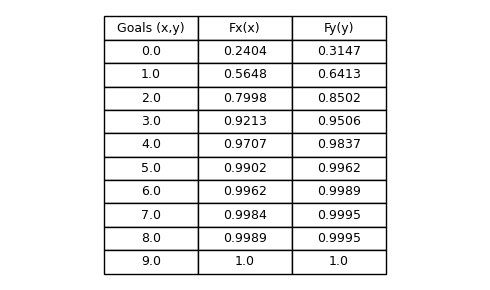

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create the DataFrame
goals = np.arange(len(home_goal_prob))
df = pd.DataFrame({
    'Goals (x,y)': goals.round(0),
    'Fx(x)': home_goal_prob,
    'Fy(y)': away_goal_prob
})

# Create a figure and axis
fig, ax = plt.subplots(figsize=(5, 3))

# Hide axes
ax.axis('off')

# Create the table
table = ax.table(cellText=df.values,
                 colLabels=df.columns,
                 cellLoc='center',
                 loc='center')

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(0.6, 1.2)

# Adjust layout and save
plt.tight_layout()
#plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Goal Cum Prob.png", dpi=300)
plt.show()

In [18]:
# Create the DataFrame
columns = np.arange(0, 10)
rows = np.arange(0, 10)
df = pd.DataFrame(index=rows, columns=columns)
for i in rows:
    for j in columns:
        df.loc[i, j] = round((df_plot[(df_plot['home GF'] <= j) & (df_plot['away GF'] <= i)].shape[0] / df_plot.shape[0]),4)



In [19]:
colLabels = [' 0 ', ' 1 ', ' 2 ', ' 3 ', ' 4 ', ' 5 ', ' 6 ', ' 7 ', ' 8 ', ' 9 ']

In [20]:
home_goal_prob[3] * away_goal_prob[3]

0.87578778

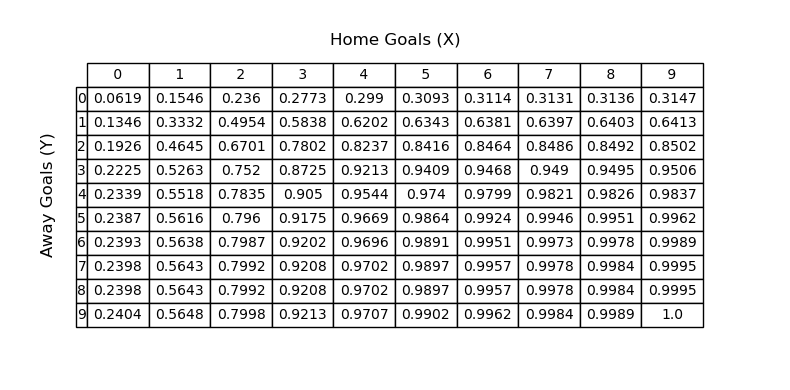

In [21]:
import matplotlib.pyplot as plt

# Assuming 'df' is your existing DataFrame

fig, ax = plt.subplots(figsize=(8, 4))  # Adjust figure size as needed

# Hide axes
ax.axis('off')

# Create the table
table = ax.table(cellText=df.values,
                 rowLabels=range(10),
                 colLabels=colLabels,
                 cellLoc='center',
                 loc='center')

# Customize the table
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(0.8, 1.2)  # Adjust the scale to fit your needs

# Add axis labels
plt.text(0.5, 0.92, 'Home Goals (X)', ha='center', va='center', transform=ax.transAxes, fontsize=12)
plt.text(0.05, 0.5, 'Away Goals (Y)', ha='center', va='center', rotation=90, transform=ax.transAxes, fontsize=12)

# Adjust layout and display the plot
plt.tight_layout()
#plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Home and Away Goal Cum Prob.png", dpi=300)
plt.show()

In [22]:
avg_home_goals

1.519262072707542

In [23]:
away_proportions = away_proportions.reindex(away_proportions.index.union([8.0])).fillna(0)

In [24]:
r1[:9]

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

In [25]:
avg_home_goals, avg_away_goals

(1.519262072707542, 1.2653282691264243)

In [26]:
df_plot['home GF'].var(), df_plot['away GF'].var()

(1.7731086842665003, 1.4751652966325643)

In [ ]:
def plot_corr(df,size=10):
    corr = df.corr()
    fig, ax = plt.subplots(figsize=(size, size))
    heatmap = ax.matshow(corr, cmap='RdBu')
    fig.colorbar(heatmap, ax=ax, fraction=0.046, pad=0.04)
    for (i, j), z in np.ndenumerate(corr):
        ax.text(j, i, '{:0.1f}'.format(z), ha='center', va='center', fontdict={'size':16})   
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.tight_layout()

In [ ]:
def plot_corr(df, size=10):
    corr = df.corr()
    fig, ax = plt.subplots(figsize=(size, size))
    
    # Create the heatmap
    heatmap = ax.matshow(corr, cmap='RdBu', vmin=-1, vmax=1)
    
    # Add color bar
    fig.colorbar(heatmap, ax=ax, fraction=0.046, pad=0.04)
    
    # Set ticks position and labels
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, fontsize=14)
    plt.yticks(range(len(corr.columns)), corr.columns, rotation=45, fontsize=14)
    
    # Add text annotations in the cells
    for (i, j), val in np.ndenumerate(corr):
        color = heatmap.cmap(heatmap.norm(val))  # Get the RGBA color for this cell
        text_color = 'white' if (color[0] * 0.299 + color[1] * 0.587 + color[2] * 0.114) < 0.5 else 'black'
        ax.text(j, i, '{:.1f}'.format(val), ha='center', va='center', color=text_color, fontsize=16)
    
    plt.tight_layout()
    plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Predictor Variables Corr Heatmap.png")
    plt.show()

In [ ]:
df_corr = df[['HT AdjGD form 5','HT Home GS form 10','HT Home GC form 10','HT prev points','HT Market Value']]

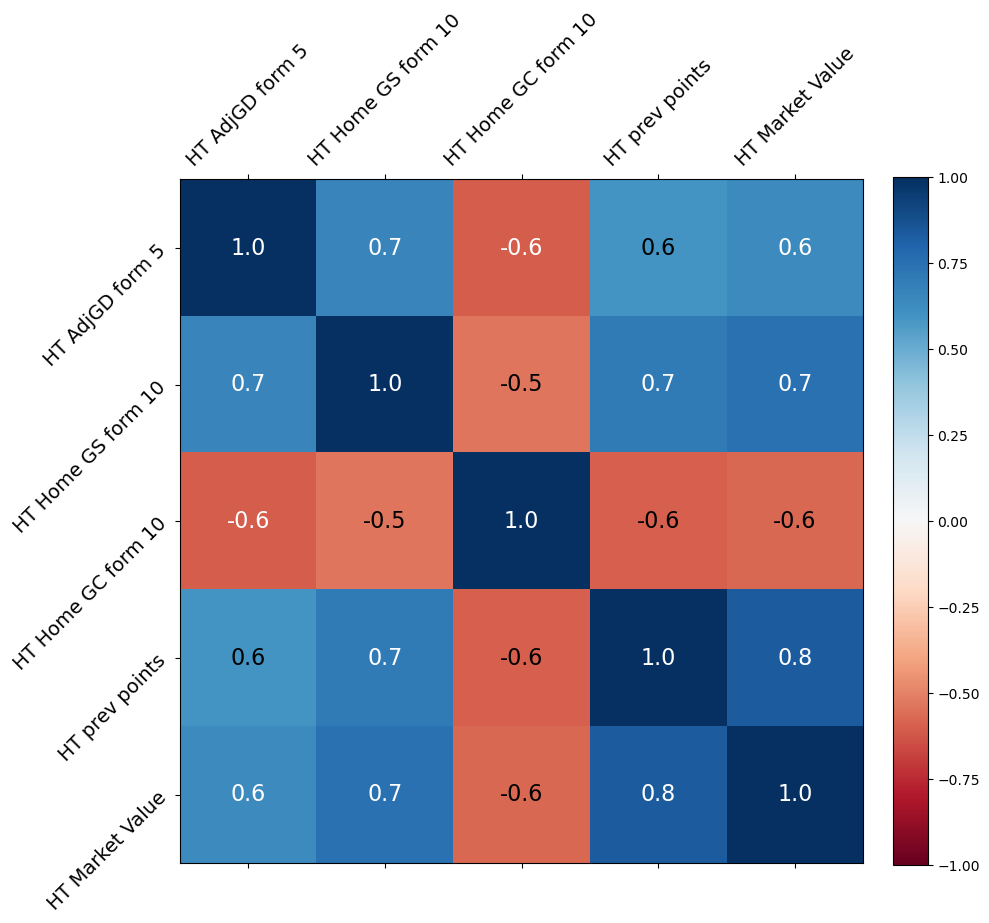

In [ ]:
plot_corr(df_corr)